In [138]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy.ndimage as nd
from PIL import Image

In [139]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/class/DIP1/DIP4E'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. object counting에 사용할 image를 grayscale로 불러오기

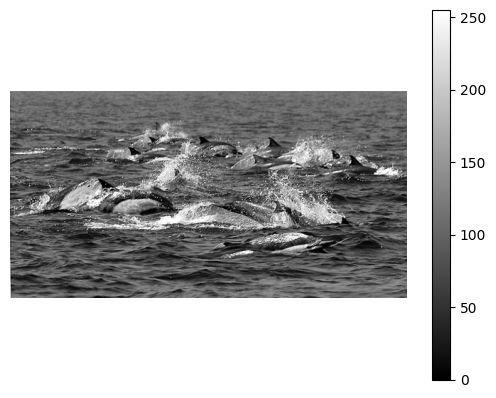

In [140]:
I = Image.open(imgpath+'/DIP4E/HW5_images.jpg').convert('L')
f = np.array(I)
f_cropped = f[50:, :]
plt.imshow(f_cropped,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 2. 적절한 전처리를 통해 영상의 noise를 줄이기

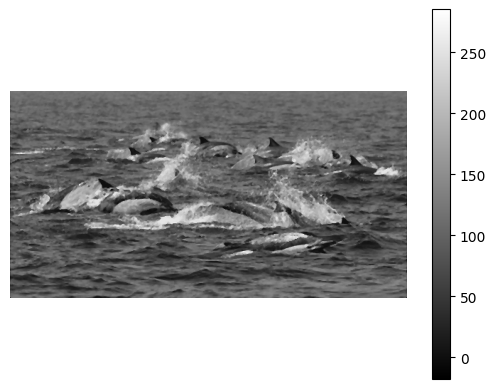

In [141]:
f_denoised = signal.medfilt2d(f_cropped, 3)



# Sobel Gradient
grad_x = cv2.Sobel(
    f_denoised.astype(np.float64),
    cv2.CV_64F, 1, 0, ksize=3
)

grad_y = cv2.Sobel(
    f_denoised.astype(np.float64),
    cv2.CV_64F, 0, 1, ksize=3
)

# Gradient Magnitude
gradient = np.sqrt(grad_x**2 + grad_y**2)

# Gradient 정규화
gradient_norm = gradient / (gradient.max() + 1e-8)

# Edge Enhancement
alpha = 0.8

blurred = cv2.GaussianBlur(
    f_denoised.astype(np.float64), (3, 3), 0
)

f_enhanced = f_denoised + alpha * gradient_norm * (
    f_denoised - blurred
)

# 결과 출력
plt.imshow(f_enhanced, cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 3. 적절한 임계값을 찾아 thresholding을 통해 binary mask를 생성하기

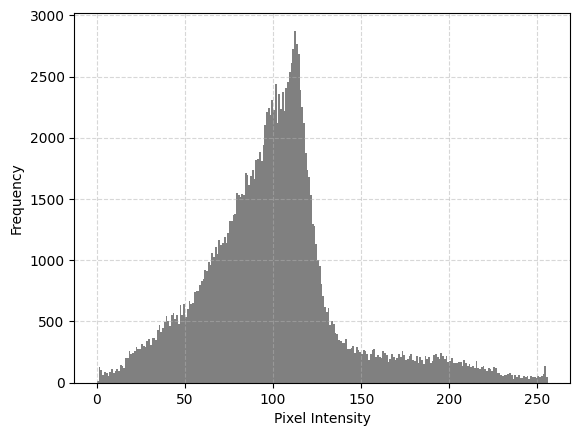

In [142]:
plt.hist(f_denoised.ravel(), bins=256, range=(0,256), color='gray')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

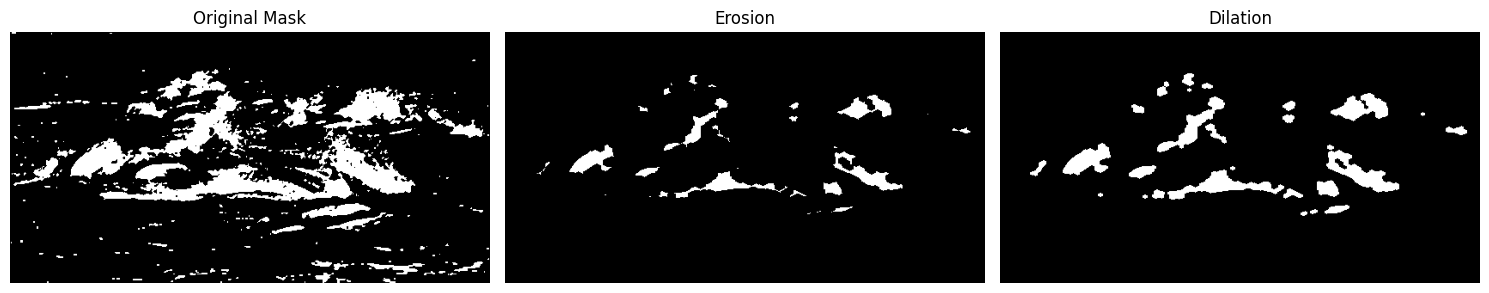

In [143]:
# 1. Thresholding
th_val = 128
f_mask = (f_denoised > th_val).astype(np.uint8)

# 2. Kernel 설정
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)

# 3. 반복 횟수 설정
erosion_iter = 2
dilation_iter = 1

# 4. Erosion
f_eroded = cv2.erode(
    f_mask,
    kernel,
    iterations=erosion_iter
)

# 5. Dilation
f_dilated = cv2.dilate(
    f_eroded,
    kernel,
    iterations=dilation_iter
)

# 6. 결과 비교
plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(f_mask, cmap='gray')
plt.title('Original Mask')
plt.axis('off')

plt.subplot(132)
plt.imshow(f_eroded, cmap='gray')
plt.title('Erosion')
plt.axis('off')

plt.subplot(133)
plt.imshow(f_dilated, cmap='gray')
plt.title('Dilation')
plt.axis('off')

plt.tight_layout()
plt.show()


## 4. Connected component 추출을 통해 object를 분리하고, 각각의 pixel수를 계산하기

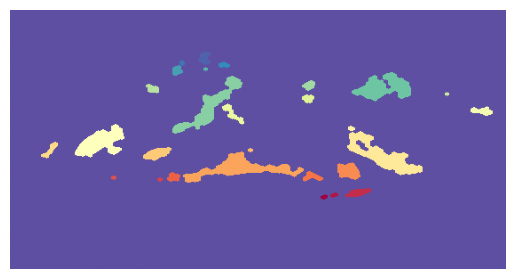

In [144]:
labels, nums = nd.label(f_dilated)
plt.imshow(labels,cmap='Spectral_r')
plt.axis('off')
plt.show()

In [145]:
cc = np.zeros((nums-1,2))
for i in range(1,nums):
  cc[i-1,0] = i
  cc[i-1,1] = np.sum(labels==i)
  print(f'index: {int(cc[i-1,0])}, number of pixels: {int(cc[i-1,1])}')

index: 1, number of pixels: 147
index: 2, number of pixels: 31
index: 3, number of pixels: 66
index: 4, number of pixels: 105
index: 5, number of pixels: 17
index: 6, number of pixels: 1205
index: 7, number of pixels: 1198
index: 8, number of pixels: 116
index: 9, number of pixels: 112
index: 10, number of pixels: 17
index: 11, number of pixels: 103
index: 12, number of pixels: 198
index: 13, number of pixels: 166
index: 14, number of pixels: 1121
index: 15, number of pixels: 36
index: 16, number of pixels: 1527
index: 17, number of pixels: 133
index: 18, number of pixels: 300
index: 19, number of pixels: 22
index: 20, number of pixels: 1525
index: 21, number of pixels: 373
index: 22, number of pixels: 146
index: 23, number of pixels: 117
index: 24, number of pixels: 22
index: 25, number of pixels: 22
index: 26, number of pixels: 188
index: 27, number of pixels: 36


## 5. 추출한 connected component 중 가장 큰 것과 작은 것을 시각화하기

In [146]:
ind_max = np.argmax(cc[:,1])
print(f'the largest component: index {int(ind_max)}, # of pixels: {int(cc[ind_max,1])}')
ind_min = np.argmin(cc[:,1])
print(f'the smallest component: index {int(ind_min)}, # of pixels: {int(cc[ind_min,1])}')

the largest component: index 15, # of pixels: 1527
the smallest component: index 4, # of pixels: 17


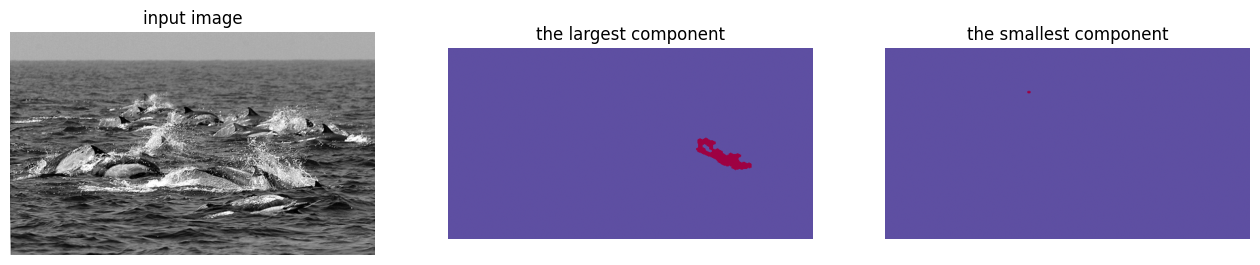

In [147]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('input image')
plt.subplot(132)
plt.imshow(labels==cc[ind_max,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the largest component')
plt.subplot(133)
plt.imshow(labels==cc[ind_min,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the smallest component')
plt.show()